In [16]:
# Salon Business Analytics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load datasets
appointments = pd.read_csv("appointments_cleaned.csv")
ab_data = pd.read_csv("ab_experiment.csv")
did_data = pd.read_csv("historical_did_weekly.csv")

# Display dataset information
print("Appointments:", appointments.shape)
print("A/B Experiment:", ab_data.shape)
print("DiD Dataset:", did_data.shape)

print("\nNotebook is ready!")

Appointments: (300000, 14)
A/B Experiment: (24000, 12)
DiD Dataset: (572, 10)

Notebook is ready!


In [17]:

# 1. DATA CLEANING AND BASIC ANALYSIS

# Check missing values
print("Missing Values:")
print(appointments.isnull().sum())

# Check and remove duplicates
print("\nDuplicate Records:", appointments.duplicated().sum())
appointments = appointments.drop_duplicates()

print("\nTotal Appointments:", len(appointments))

# Appointment status
print("\nAppointment Status:")
print(appointments["appointment_status"].value_counts())

# Revenue from completed appointments
completed = appointments[
    appointments["appointment_status"] == "completed"
]

total_revenue = completed["amount_paid"].sum()

print("\nTotal Revenue: ₹", round(total_revenue, 2))

# Revenue by service
print("\nRevenue by Service:")
print(
    completed.groupby("service_category")["amount_paid"]
    .sum()
    .sort_values(ascending=False)
)

# No-show rate
print("\nNo-show Rate:")
print(round(appointments["no_show_flag"].mean() * 100, 2), "%")

# Customer retention
customer_visits = completed.dropna(
    subset=["client_id"]
).groupby("client_id").size()

returning = (customer_visits >= 2).sum()
total_customers = len(customer_visits)

print("\nTotal Identifiable Customers:", total_customers)
print("Returning Customers:", returning)
print(
    "Retention Rate:",
    round(returning / total_customers * 100, 2),
    "%"
)

print("\nAnalysis completed!")


Missing Values:
appointment_id              0
appointment_datetime        0
outlet_id                   0
client_id               35911
is_walk_in                  0
stylist_id                450
service_name_raw            0
service_category            0
appointment_status          0
cancellation_reason         0
no_show_flag                0
listed_price                0
discount_amount             0
amount_paid                 0
dtype: int64

Duplicate Records: 0

Total Appointments: 300000

Appointment Status:
appointment_status
completed    251690
cancelled     48310
Name: count, dtype: int64

Total Revenue: ₹ 245698046.21

Revenue by Service:
service_category
Facial         61158994.26
Hair Colour    52269955.17
Massage        50311568.95
Haircut        31843264.40
Pedicure       18198644.33
Manicure       17191695.79
Waxing         14723923.31
Name: amount_paid, dtype: float64

No-show Rate:
9.37 %

Total Identifiable Customers: 67077
Returning Customers: 57587
Retention Rate: 8

In [18]:

# 2. A/B TESTING

control = ab_data[ab_data["assigned_group"] == "Control"]
treatment = ab_data[ab_data["assigned_group"] == "Treatment"]

print("Control group:", len(control))
print("Treatment group:", len(treatment))

# Calculate group averages
metrics = ["retained_30d", "revenue_per_visit", "no_show_rate"]

for metric in metrics:
    c = control[metric].mean()
    t = treatment[metric].mean()

    print("\nMetric:", metric)
    print("Control:", round(c, 4))
    print("Treatment:", round(t, 4))
    print("Difference:", round(t - c, 4))

    # Statistical test
    result = stats.ttest_ind(
        treatment[metric],
        control[metric],
        equal_var=False
    )

    print("P-value:", round(result.pvalue, 6))

    if result.pvalue < 0.05:
        print("Result: Statistically significant")
    else:
        print("Result: Not statistically significant")

print("\nA/B testing completed!")


Control group: 12000
Treatment group: 12000

Metric: retained_30d
Control: 0.4156
Treatment: 0.4661
Difference: 0.0505
P-value: 0.0
Result: Statistically significant

Metric: revenue_per_visit
Control: 1566.715
Treatment: 1625.8412
Difference: 59.1262
P-value: 0.0
Result: Statistically significant

Metric: no_show_rate
Control: 0.0954
Treatment: 0.0946
Difference: -0.0008
P-value: 0.797005
Result: Not statistically significant

A/B testing completed!


In [19]:

# 3. CONFIDENCE INTERVALS

from scipy.stats import t, norm

for metric in ["retained_30d", "revenue_per_visit", "no_show_rate"]:

    c = control[metric].dropna()
    tr = treatment[metric].dropna()

    difference = tr.mean() - c.mean()

    if metric == "revenue_per_visit":
        # Welch confidence interval
        se = np.sqrt(tr.var(ddof=1)/len(tr) + c.var(ddof=1)/len(c))
        df = (tr.var(ddof=1)/len(tr) + c.var(ddof=1)/len(c))**2 / (
            (tr.var(ddof=1)/len(tr))**2/(len(tr)-1) +
            (c.var(ddof=1)/len(c))**2/(len(c)-1)
        )
        margin = t.ppf(0.975, df) * se

    else:
        # Confidence interval for two proportions
        se = np.sqrt(
            tr.mean()*(1-tr.mean())/len(tr) +
            c.mean()*(1-c.mean())/len(c)
        )
        margin = norm.ppf(0.975) * se

    print("\n", metric)
    print("Difference:", round(difference, 4))
    print("95% CI:", round(difference-margin, 4),
          "to", round(difference+margin, 4))

print("\nConfidence intervals completed!")



 retained_30d
Difference: 0.0505
95% CI: 0.038 to 0.063

 revenue_per_visit
Difference: 59.1262
95% CI: 48.5102 to 69.7421

 no_show_rate
Difference: -0.0008
95% CI: -0.0082 to 0.0066

Confidence intervals completed!


In [20]:

# 4. RANDOMISATION AND SRM CHECK

from scipy.stats import chisquare, chi2_contingency

# Check group sizes (SRM)
counts = ab_data["assigned_group"].value_counts()

print("Group sizes:")
print(counts)

total = len(ab_data)
expected = [total / 2, total / 2]

actual = [
    counts.get("Control", 0),
    counts.get("Treatment", 0)
]

chi, p = chisquare(actual, f_exp=expected)

print("\nSRM p-value:", p)

if p < 0.05:
    print("SRM detected: Check randomisation!")
else:
    print("No SRM detected. Group sizes are balanced.")

# Check customer characteristics
print("\nRandomisation Balance:")

for column in ["age", "prior_90d_visits", "baseline_90d_spend"]:

    result = stats.ttest_ind(
        control[column],
        treatment[column],
        equal_var=False
    )

    print("\n", column)
    print("P-value:", round(result.pvalue, 4))

# Check membership balance
table = pd.crosstab(
    ab_data["assigned_group"],
    ab_data["membership_flag"]
)

chi, p, dof, expected = chi2_contingency(table)

print("\nMembership balance p-value:", round(p, 4))

print("\nRandomisation checks completed!")


Group sizes:
assigned_group
Control      12000
Treatment    12000
Name: count, dtype: int64

SRM p-value: 1.0
No SRM detected. Group sizes are balanced.

Randomisation Balance:

 age
P-value: 0.5829

 prior_90d_visits
P-value: 0.0789

 baseline_90d_spend
P-value: 0.3497

Membership balance p-value: 0.3052

Randomisation checks completed!


In [21]:

# 5. CUSTOMER SEGMENT ANALYSIS

segments = {
    "Members": ab_data["membership_flag"] == 1,
    "Non-members": ab_data["membership_flag"] == 0,
    "Below 30": ab_data["age"] < 30,
    "Age 30-44": (ab_data["age"] >= 30) & (ab_data["age"] <= 44),
    "Age 45+": ab_data["age"] >= 45,
    "0-1 Previous Visits": ab_data["prior_90d_visits"] <= 1,
    "2-3 Previous Visits": ab_data["prior_90d_visits"].between(2, 3),
    "4+ Previous Visits": ab_data["prior_90d_visits"] >= 4
}

for name, condition in segments.items():

    data = ab_data[condition]

    c = data[data["assigned_group"] == "Control"]
    tr = data[data["assigned_group"] == "Treatment"]

    control_rate = c["retained_30d"].mean() * 100
    treatment_rate = tr["retained_30d"].mean() * 100

    difference = treatment_rate - control_rate

    print("\nSegment:", name)
    print("Control retention:", round(control_rate, 2), "%")
    print("Treatment retention:", round(treatment_rate, 2), "%")
    print("Improvement:", round(difference, 2), "percentage points")

print("\nSegment analysis completed!")



Segment: Members
Control retention: 46.34 %
Treatment retention: 51.2 %
Improvement: 4.86 percentage points

Segment: Non-members
Control retention: 38.62 %
Treatment retention: 43.86 %
Improvement: 5.24 percentage points

Segment: Below 30
Control retention: 42.53 %
Treatment retention: 47.55 %
Improvement: 5.02 percentage points

Segment: Age 30-44
Control retention: 41.18 %
Treatment retention: 46.31 %
Improvement: 5.13 percentage points

Segment: Age 45+
Control retention: 41.26 %
Treatment retention: 46.28 %
Improvement: 5.02 percentage points

Segment: 0-1 Previous Visits
Control retention: 40.44 %
Treatment retention: 45.27 %
Improvement: 4.83 percentage points

Segment: 2-3 Previous Visits
Control retention: 41.98 %
Treatment retention: 46.83 %
Improvement: 4.84 percentage points

Segment: 4+ Previous Visits
Control retention: 41.58 %
Treatment retention: 46.95 %
Improvement: 5.37 percentage points

Segment analysis completed!


In [22]:

# 6. DIFFERENCE-IN-DIFFERENCES ANALYSIS

import statsmodels.formula.api as smf

# Create treatment and post-intervention variables
did_data["treatment"] = (
    did_data["group"].astype(str).str.lower().str.strip() == "treatment"
).astype(int)

did_data["post"] = (
    did_data["post_intervention"].astype(int)
)

did_data["treatment_post"] = (
    did_data["treatment"] * did_data["post"]
)

# Run DiD models
outcomes = [
    "retention_rate",
    "revenue_per_visit",
    "no_show_rate"
]

for outcome in outcomes:

    model = smf.ols(
        f"{outcome} ~ treatment_post + C(outlet_id) + C(week)",
        data=did_data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": did_data["outlet_id"]}
    )

    effect = model.params["treatment_post"]
    p_value = model.pvalues["treatment_post"]
    ci = model.conf_int().loc["treatment_post"]

    print("\nOutcome:", outcome)
    print("DiD Effect:", round(effect, 4))
    print("95% CI:", round(ci[0], 4), "to", round(ci[1], 4))
    print("P-value:", round(p_value, 6))

print("\nDiD analysis completed!")



Outcome: retention_rate
DiD Effect: 0.0331
95% CI: 0.029 to 0.0373
P-value: 0.0

Outcome: revenue_per_visit
DiD Effect: 77.7116
95% CI: 66.8168 to 88.6064
P-value: 0.0

Outcome: no_show_rate
DiD Effect: -0.0198
95% CI: -0.0224 to -0.0172
P-value: 0.0

DiD analysis completed!


In [23]:

# PRE-TREND TEST

for outcome in ["retention_rate", "revenue_per_visit", "no_show_rate"]:

    model = smf.ols(
        f"{outcome} ~ week_number + treatment:week_number + C(outlet_id)",
        data=pre_data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": pre_data["outlet_id"]}
    )

    term = "treatment:week_number"

    print("\nOutcome:", outcome)
    print("Trend difference:", round(model.params[term], 6))
    print("P-value:", round(model.pvalues[term], 4))

print("\nPre-trend test completed!")



Outcome: retention_rate
Trend difference: 0.000418
P-value: 0.1873

Outcome: revenue_per_visit
Trend difference: 1.07997
P-value: 0.3942

Outcome: no_show_rate
Trend difference: -0.00052
P-value: 0.0523

Pre-trend test completed!


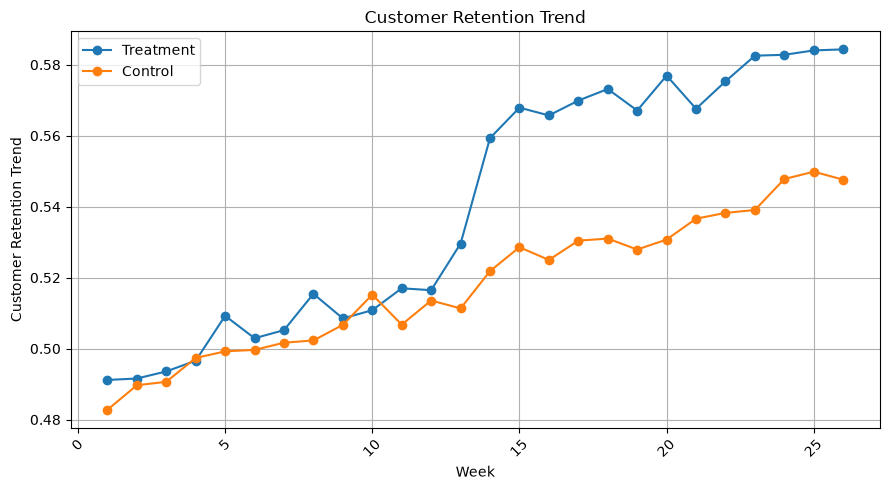

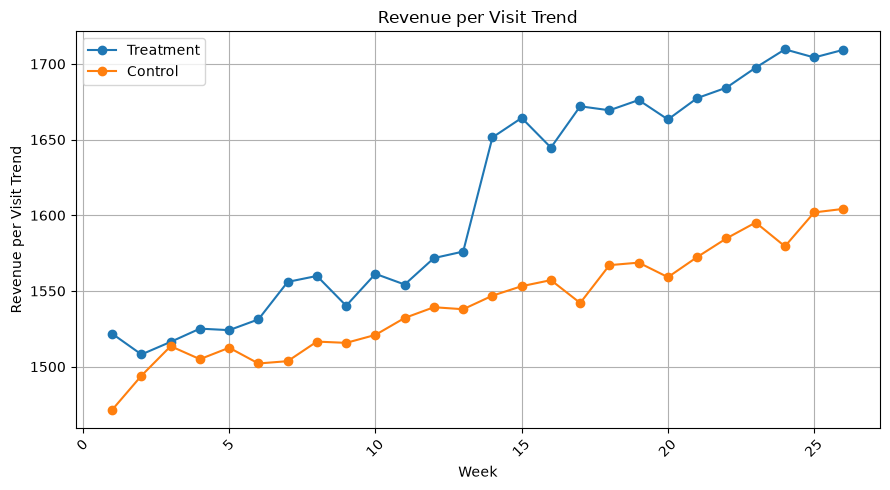

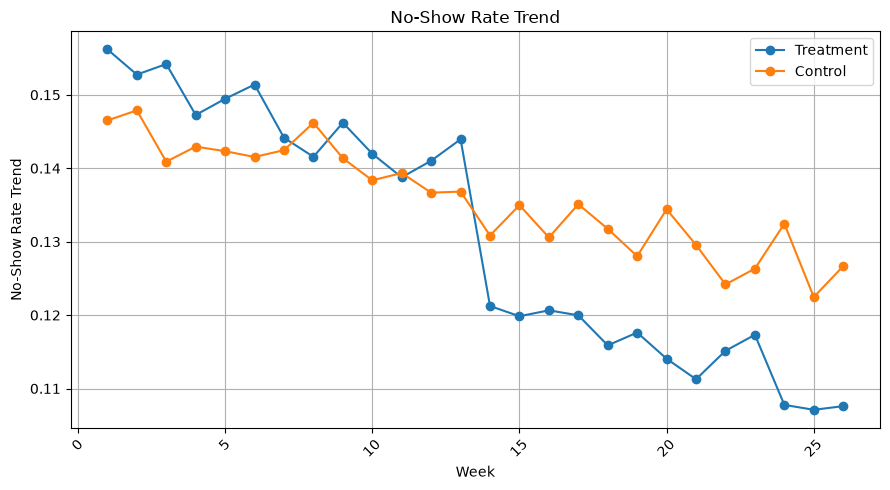

All 3 graphs created and saved!


In [24]:

# 8. DATA VISUALIZATION

graphs = [
    ("retention_rate", "Customer Retention Trend"),
    ("revenue_per_visit", "Revenue per Visit Trend"),
    ("no_show_rate", "No-Show Rate Trend")
]

for outcome, title in graphs:

    plt.figure(figsize=(9, 5))

    for group in ["Treatment", "Control"]:

        data = did_data[did_data["group"] == group]

        trend = data.groupby("week")[outcome].mean().sort_index()

        plt.plot(
            trend.index,
            trend.values,
            marker="o",
            label=group
        )

    plt.title(title)
    plt.xlabel("Week")
    plt.ylabel(title)
    plt.legend()
    plt.grid()
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        title.lower().replace(" ", "_") + ".png"
    )

    plt.show()

print("All 3 graphs created and saved!")


In [25]:

# 9. FINAL PROJECT CONCLUSION

print("=" * 50)
print("SALON BUSINESS ANALYTICS - FINAL CONCLUSION")
print("=" * 50)

print("""
1. The dataset contains 300,000 appointment records.

2. Customer retention was 85.85% among identifiable
   customers with completed appointments.

3. A/B testing showed:
   - Retention improved by 5.05 percentage points.
   - Revenue per visit increased by Rs. 59.13.
   - No significant change in no-show rate.

4. Randomisation checks found no SRM or significant
   imbalance in the measured customer characteristics.

5. Segment analysis showed positive retention
   improvements across all tested segments.

6. DiD estimated:
   - Retention improvement: 3.31 percentage points.
   - Revenue improvement: Rs. 77.71 per visit.
   - No-show reduction: 1.98 percentage points.

7. Pre-trend tests found no significant differences,
   but the no-show result was borderline.

FINAL RECOMMENDATION:
GO WITH MONITORING.

IMPORTANT LIMITATIONS:
- All datasets are synthetic.
- Only 22 outlets were used in DiD.
- Parallel trends cannot be proven.
- Results should not be treated as real business outcomes.
""")

print("=" * 50)
print("PROJECT ANALYSIS COMPLETED!")
print("=" * 50)


SALON BUSINESS ANALYTICS - FINAL CONCLUSION

1. The dataset contains 300,000 appointment records.

2. Customer retention was 85.85% among identifiable
   customers with completed appointments.

3. A/B testing showed:
   - Retention improved by 5.05 percentage points.
   - Revenue per visit increased by Rs. 59.13.
   - No significant change in no-show rate.

4. Randomisation checks found no SRM or significant
   imbalance in the measured customer characteristics.

5. Segment analysis showed positive retention
   improvements across all tested segments.

6. DiD estimated:
   - Retention improvement: 3.31 percentage points.
   - Revenue improvement: Rs. 77.71 per visit.
   - No-show reduction: 1.98 percentage points.

7. Pre-trend tests found no significant differences,
   but the no-show result was borderline.

FINAL RECOMMENDATION:
GO WITH MONITORING.

IMPORTANT LIMITATIONS:
- All datasets are synthetic.
- Only 22 outlets were used in DiD.
- Parallel trends cannot be proven.
- Results s